# TCGA expression imputation

## Introduction

This benchmark compares masked-expression reconstruction by frozen BridgeRNA, BulkFormer, and training-derived gene-expression baselines on a fixed TCGA cohort.

The notebook reads saved results; model inference and metric generation are performed by the benchmark pipeline.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT / 'config.json').exists():
    ROOT = ROOT / 'benchmarks' / 'imputation'
RESULTS = ROOT / 'results'
config = json.loads((ROOT / 'config.json').read_text())
summary_path = RESULTS / 'summary_results.csv'
print('Run complete' if summary_path.exists() else 'Fresh inference is pending or running; final scores are not available yet.')

Run complete


## Data and methods

- The frozen cohort contains 1,000 randomly selected TCGA primary-tumor samples. Cancer types are not balanced. The saved cohort manifest defines sample identity and order.
- BridgeRNA uses 15,165 canonical genes, of which 15,105 have measured TCGA expression. BulkFormer uses 20,010 genes, of which 18,949 are measured. HGNC mapping gives 15,101 unambiguous shared targets.
- Inputs use each checkpoint's intended natural `log1p(TPM)` preprocessing. Gene lengths and TPM denominators differ between model target spaces; cross-model MSE therefore does not measure error against identical numerical targets.
- This analysis masks each model's own measured genes. Samples, masking ratios, and seeds are matched, but evaluated gene sets and exact masks differ between vocabularies. This is not a matched-target comparison.
- Mask ratios are 15%, 30%, 50%, 70%, 90%, and 100%, with the same 3 mask seeds for every model. All backbones and checkpoints remain frozen; a seed repeats masking, not training.
- Training-gene mean and median are frozen profiles derived from 5,000 ARCHS4 human training samples, without using TCGA evaluation expression. Mean and median in both target spaces are retained numerically; figures display only the training mean for BRIDGE genes to avoid overlapping baseline curves.
- Pearson, Spearman, and MSE are calculated per sample on masked positions only, averaged across samples within each seed, then summarized across seeds. Error bars show mask-seed SD, not confidence intervals across patients. Undefined correlations are counted explicitly and are not replaced with zero.

In [2]:
display(pd.read_csv(RESULTS / 'cohort_manifest.csv').groupby('cancer_type').size().rename('samples').to_frame())
if (RESULTS / 'run_provenance.json').exists():
    display(json.loads((RESULTS / 'run_provenance.json').read_text()))

,samples
cancer_type,
Adrenocortical Carcinoma,10
Bladder Urothelial Carcinoma,44
Brain Lower Grade Glioma,53
Breast Invasive Carcinoma,118
Cervical Squamous Cell Carcinoma and Endocervical Adenocarcinoma,30
Cholangiocarcinoma,1
Colon Adenocarcinoma,32
Esophageal Carcinoma,23
Glioblastoma Multiforme,15


{'status': 'complete',
 'started_utc': '2026-11-08T01:14:34Z',
 'config': {'selection_seed': 20260827,
  'num_samples': 1000,
  'mask_ratios': [0.15, 0.3, 0.5, 0.7, 0.9, 1.0],
  'mask_seeds': [0, 1, 2],
  'mask_token': -10.0,
  'device': 'cuda',
  'batch_sizes': {'ours_45.6m': 4,
   'bulkformer_50m': 32,
   'bulkformer_147m': 16},
  'benchmark_modes': ['native_vocab']},
 'input_sha256': {'benchmarks/imputation/work/bulkformer_genes.parquet': '8fde6cf8ad0c687995e633025196d9bfa4436836b4f757976e33b47cdf2cd5d0',
  'benchmarks/imputation/work/bulkformer_log1p_tpm.npy': '5bf116fc70e991ed6172209f54153cb81045f13eb9208d6978056de1937668b0',
  'benchmarks/imputation/work/frozen_training_gene_baselines.npz': '68a30b4040a4887bc009b40bd8eb1f09cf214b3fd936e3d7eca1f173203286a2',
  'benchmarks/imputation/work/launcher.pid': 'ae9dae23a4e57a4dabac5913500f7f8d2f053d286ec54eb1040d455f0e3625ce',
  'benchmarks/imputation/work/ours_genes.parquet': '3c401f93feb4e8c4bbfa80d39daf977309984ca1390df895ffbaa8aa98def

## Native-gene reconstruction

Models are evaluated on their own measured native gene panels. Colors identify methods. Training-gene mean is calculated from ARCHS4 training samples and scored on the BRIDGE gene panel with its preprocessing; it is not a BRIDGE model prediction. Model error bars and the thin shaded baseline band show SD across three mask seeds. At 100% masking, no measured expression is available. Different evaluated gene sets limit direct cross-model comparisons.

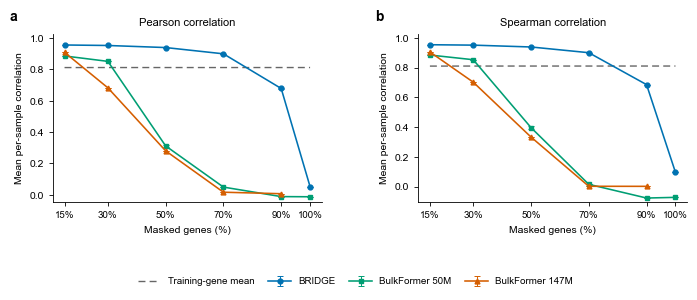

In [3]:
if summary_path.exists():
    import sys
    sys.path.insert(0, str(ROOT / 'pipeline'))
    from plot_figures import render, save_style_provenance
    summary = pd.read_csv(summary_path)
    fig = render(summary, ['pearson', 'spearman'], RESULTS, 'native_imputation_correlations')
    plt.show()
    save_style_provenance(RESULTS)

## Reconstruction error

MSE is shown separately because models use different gene panels, gene lengths, and TPM denominators. Values describe error within each native target space; they are not a comparison against identical numerical targets. Error bars show SD across three mask seeds.

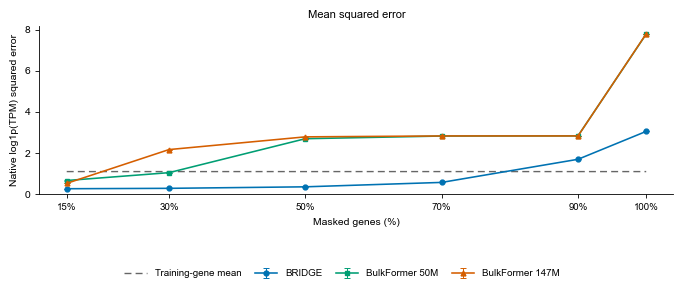

,benchmark,method,target_space,mask_ratio,pearson_mean,pearson_std,spearman_mean,spearman_std,mse_mean,mse_std,seeds,pearson_defined_min,spearman_defined_min
0,native_vocab,bulkformer_147m,bulkformer,0.15,0.908515,0.000150,0.904769,0.000250,0.510923,0.001216,3,1000,1000
1,native_vocab,bulkformer_147m,bulkformer,0.30,0.682250,0.001892,0.701747,0.001725,2.154689,0.001536,3,1000,1000
2,native_vocab,bulkformer_147m,bulkformer,0.50,0.280258,0.001721,0.332558,0.001544,2.774246,0.000632,3,999,998
3,native_vocab,bulkformer_147m,bulkformer,0.70,0.016387,0.001017,0.001647,0.000744,2.818755,0.000354,3,966,915
4,native_vocab,bulkformer_147m,bulkformer,0.90,0.006810,0.000239,0.001172,0.000318,2.818995,0.000170,3,941,847
5,native_vocab,bulkformer_147m,bulkformer,1.00,NaN,NaN,NaN,NaN,7.790097,0.000000,3,0,0
6,native_vocab,bulkformer_50m,bulkformer,0.15,0.885505,0.000342,0.884141,0.000297,0.648941,0.001503,3,1000,1000
7,native_vocab,bulkformer_50m,bulkformer,0.30,0.851044,0.000670,0.852665,0.000619,1.030908,0.004671,3,1000,1000
8,native_vocab,bulkformer_50m,bulkformer,0.50,0.311743,0.008222,0.396284,0.009119,2.684120,0.003980,3,1000,1000
9,native_vocab,bulkformer_50m,bulkformer,0.70,0.049033,0.001036,0.014825,0.000831,2.814330,0.000379,3,1000,1000


In [4]:
if summary_path.exists():
    fig = render(summary, ['mse'], RESULTS, 'native_imputation_mse')
    plt.show()
    display(summary.round(6))

## Quality control and cancer-specific performance

Correlation can be undefined when predictions are constant. The QC table reports how many of the 1,000 samples have defined correlations for each condition. Per-cancer tables and the unweighted cancer-type mean provide a secondary view without changing the frozen cohort.

In [5]:
if summary_path.exists():
    qc = pd.read_csv(RESULTS / 'correlation_qc.csv')
    display(qc[(qc.pearson_defined < qc.samples) | (qc.spearman_defined < qc.samples)])
    macro = pd.read_csv(RESULTS / 'cancer_macro_per_seed.csv')
    display(macro.groupby(['benchmark', 'method', 'target_space', 'mask_ratio'])[['pearson', 'spearman', 'mse']].mean().round(6))

,benchmark,method,target_space,mask_ratio,mask_seed,samples,pearson_defined,spearman_defined
6,native_vocab,bulkformer_147m,bulkformer,0.5,0,1000,1000,998
7,native_vocab,bulkformer_147m,bulkformer,0.5,1,1000,999,998
8,native_vocab,bulkformer_147m,bulkformer,0.5,2,1000,999,999
9,native_vocab,bulkformer_147m,bulkformer,0.7,0,1000,980,915
10,native_vocab,bulkformer_147m,bulkformer,0.7,1,1000,966,923
11,native_vocab,bulkformer_147m,bulkformer,0.7,2,1000,973,916
12,native_vocab,bulkformer_147m,bulkformer,0.9,0,1000,943,853
13,native_vocab,bulkformer_147m,bulkformer,0.9,1,1000,941,847
14,native_vocab,bulkformer_147m,bulkformer,0.9,2,1000,951,874
15,native_vocab,bulkformer_147m,bulkformer,1.0,0,1000,0,0


pearson  spearman  \
benchmark    method            target_space mask_ratio                       
native_vocab bulkformer_147m   bulkformer   0.15        0.904775  0.900650   
                                            0.30        0.683860  0.704446   
                                            0.50        0.288011  0.342449   
                                            0.70        0.017266  0.002276   
                                            0.90        0.007257  0.001938   
                                            1.00             NaN       NaN   
             bulkformer_50m    bulkformer   0.15        0.883723  0.882254   
                                            0.30        0.848064  0.849547   
                                            0.50        0.314806  0.395053   
                                            0.70        0.048856  0.012207   
                                            0.90       -0.010432 -0.076674   
                                            1.00       -0.011977 -0.072752   
             ours_45.6m        ours         0.15        0.953007  0.950979   
                                            0.30        0.949761  0.948328   
                                            0.50        0.936803  0.936314   
                                            0.70        0.897477  0.898493   
                                            0.90        0.677411  0.684948   
                                            1.00        0.052805  0.098395   
             train_gene_mean   bulkformer   0.15        0.809930  0.820249   
                                            0.30        0.809689  0.820243   
                                            0.50        0.809709  0.820244   
                                            0.70        0.809603  0.820158   
                                            0.90        0.809685  0.820286   
                                            1.00        0.809712  0.820299   
                               ours         0.15        0.810562  0.809327   
                                            0.30        0.810637  0.809430   
                                            0.50        0.810592  0.809449   
                                            0.70        0.810495  0.809387   
                                            0.90        0.810545  0.809419   
                                            1.00        0.810583  0.809456   
             train_gene_median bulkformer   0.15        0.793692  0.805230   
                                            0.30        0.793361  0.805124   
                                            0.50        0.793379  0.805176   
                                            0.70        0.793242  0.805031   
                                            0.90        0.793332  0.805198   
                                            1.00        0.793367  0.805204   
                               ours         0.15        0.798065  0.800847   
                                            0.30        0.798219  0.801056   
                                            0.50        0.798144  0.801001   
                                            0.70        0.797996  0.800909   
                                            0.90        0.798061  0.800940   
                                            1.00        0.798115  0.800994   

                                                             mse  
benchmark    method            target_space mask_ratio            
native_vocab bulkformer_147m   bulkformer   0.15        0.525225  
                                            0.30        2.140253  
                                            0.50        2.762066  
                                            0.70        2.811356  
                                            0.90        2.811633  
                                            1.00        7.666867  
             bulkformer_50m    bulkformer   0.15        0.656307  
                     

## Interpretation and limitations

Interpretation must follow the fresh results shown above. Higher correlation under this protocol supports more accurate reconstruction of masked expression patterns, rather than a claim of universal model superiority. Each model is evaluated on a different gene panel; score differences cannot be attributed to model quality alone. Cross-model MSE remains sensitive to model-specific preprocessing. Random gene masking does not reproduce every experimental missingness mechanism, and TCGA sample or study exposure during model pretraining has not been established here. Cancer-specific summaries do not make the cohort balanced.

## Reproduce the analysis

See `README.md` for preparation, pilot, inference, aggregation, and report commands. Expensive inference is performed only by the pipeline, never automatically by this notebook.